# Premium Customer Churn Prediction

Portfolio analysis by **Nicolas Ernesto Juez Castañeda**.

This notebook summarizes a privacy-conscious rebuild of the GCI World April 2026
final assignment. The reusable implementation lives in `src/churn_model`; this
notebook presents the validated aggregate results and the exact training workflow.

The original course data is not distributed. See `data/README.md`.

## 1. Business objective

Rank customers in the top revenue quartile by near-term churn risk so that a
retention team can test targeted interventions. The model is a decision-support
prototype, not an automated customer-treatment system.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
REPORTS = ROOT / "reports"

metrics = json.loads((REPORTS / "metrics.json").read_text(encoding="utf-8"))
comparison = pd.read_csv(REPORTS / "model_comparison.csv")
comparison.round(4)

,model,roc_auc,pr_auc,accuracy,precision,recall,f1,brier_score
0,xgboost,0.6652,0.6479,0.6191,0.6155,0.5747,0.5944,0.2289
1,random_forest,0.6474,0.6302,0.6049,0.5930,0.5945,0.5938,0.2340
2,logistic_regression,0.6342,0.6048,0.6029,0.5975,0.5587,0.5774,0.2375
3,dummy,0.5000,0.4857,0.5143,0.0000,0.0000,0.0000,0.2498


## 2. Validated cohort

- 100,000 merged customer records.
- 25,005 customers at or above the 75th percentile of average revenue.
- 20,004 training rows and 5,001 untouched holdout rows.
- 76 model features after excluding identifiers and 22 sensitive or proxy fields.

In [2]:
pd.Series(metrics["dataset"], name="value").to_frame()

,value
churn_rate,0.485663
excluded_constant_columns,[]
excluded_high_missingness_columns,[]
excluded_sensitive_columns,"[HHstatin, adults, area, asl_flag, crclscod, c..."
model_feature_count,76
premium_revenue_cutoff,69.48
premium_revenue_quantile,0.75
random_state,42
segment_rows,25005
segment_share,0.25005


## 3. Leakage-safe training flow

The preprocessing pipeline is fitted separately inside each estimator. Numerical
values are median-imputed and standardized; categorical values are mode-imputed
and one-hot encoded. All fitting occurs on training data. XGBoost hyperparameters
are selected with five-fold stratified cross-validation without touching the final
holdout set.

In [3]:
# Reproduce locally when authorized source files are available.
from sklearn.model_selection import train_test_split

from churn_model.data import (
    load_and_merge,
    select_model_features,
    select_premium_segment,
)

client_path = ROOT / "data" / "raw" / "Client.csv"
record_path = ROOT / "data" / "raw" / "Record.csv"

if client_path.exists() and record_path.exists():
    merged = load_and_merge(client_path, record_path)
    premium, cutoff = select_premium_segment(merged, revenue_quantile=0.75)
    selected = select_model_features(premium)
    X_train, X_test, y_train, y_test = train_test_split(
        selected.X,
        selected.y,
        test_size=0.20,
        stratify=selected.y,
        random_state=42,
    )
    print(f"Ready to train: {len(X_train):,} training and {len(X_test):,} holdout rows")
else:
    print("Private course data not found. Displaying committed aggregate results instead.")

Private course data not found. Displaying committed aggregate results instead.


## 4. Model comparison

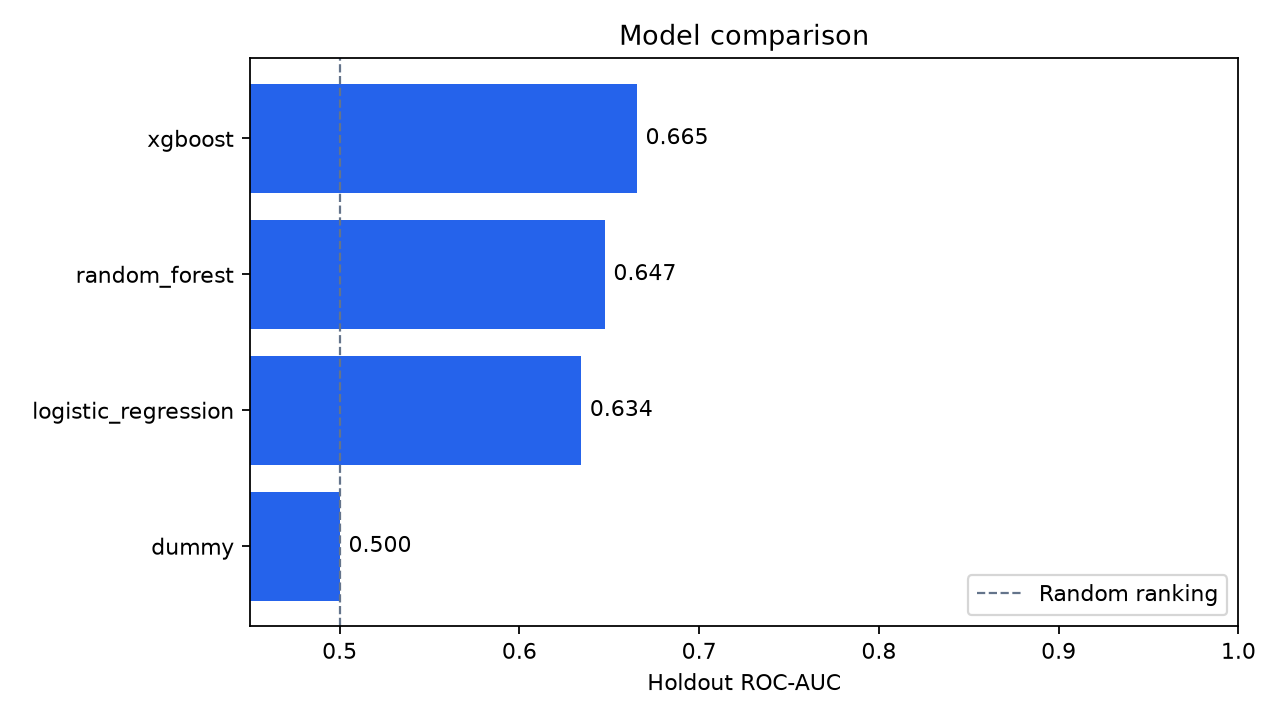

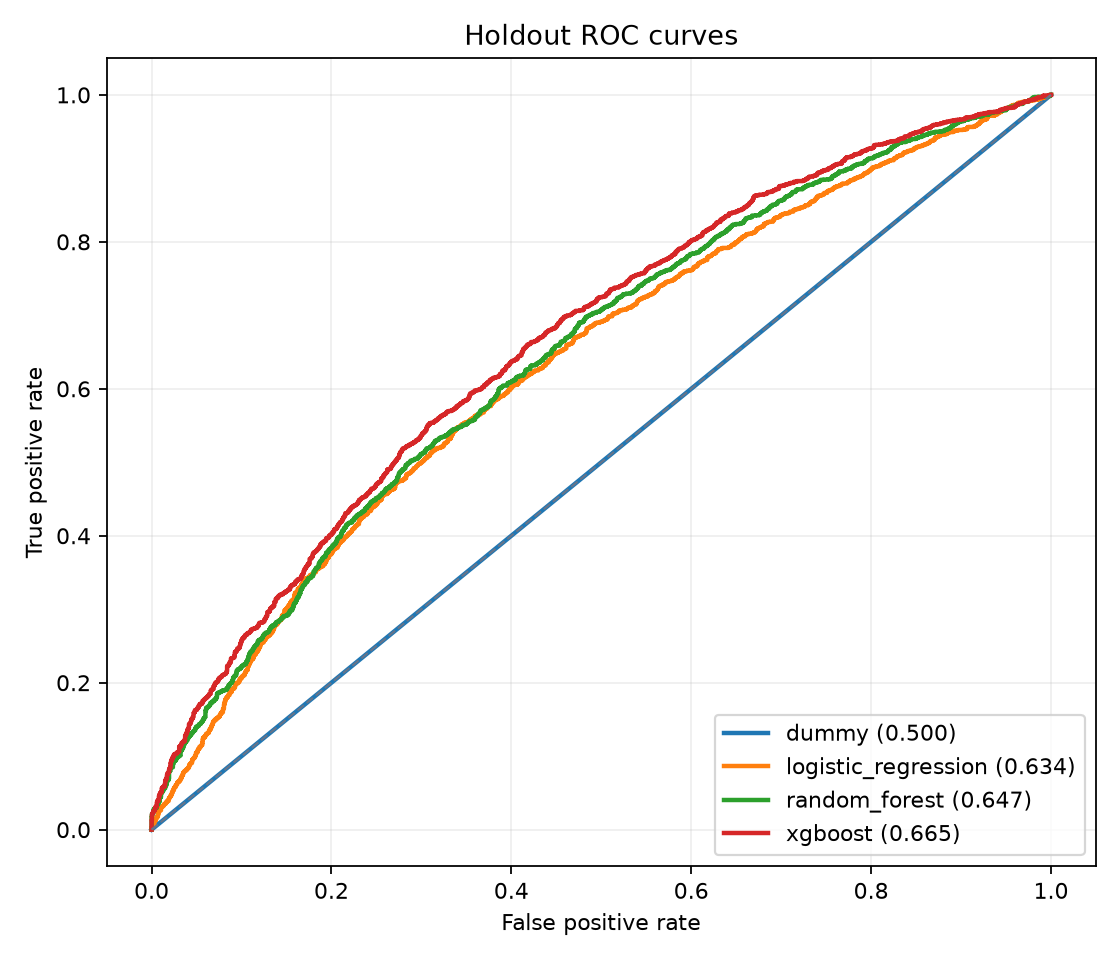

In [4]:
display(Image(filename=REPORTS / "figures" / "model_comparison.png"))
display(Image(filename=REPORTS / "figures" / "roc_curves.png"))

The tuned XGBoost model achieved **0.6652 ROC-AUC** and **0.6479 PR-AUC** on the
untouched holdout set. The result is meaningfully above the dummy baseline, but it
is not strong enough to justify autonomous interventions.

## 5. Error analysis

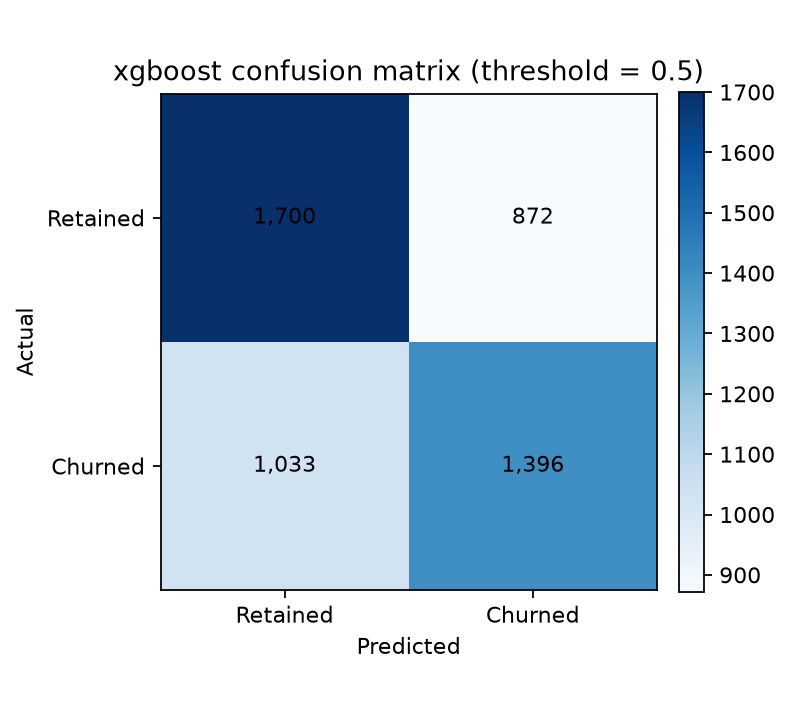

In [5]:
display(Image(filename=REPORTS / "figures" / "confusion_matrix.png"))

At the default 0.5 threshold, the selected model reaches 61.91% accuracy and
59.44% F1. A real retention program should choose its threshold using the cost of
contact, offer value, expected customer lifetime value, and intervention capacity.

## 6. Feature interpretation

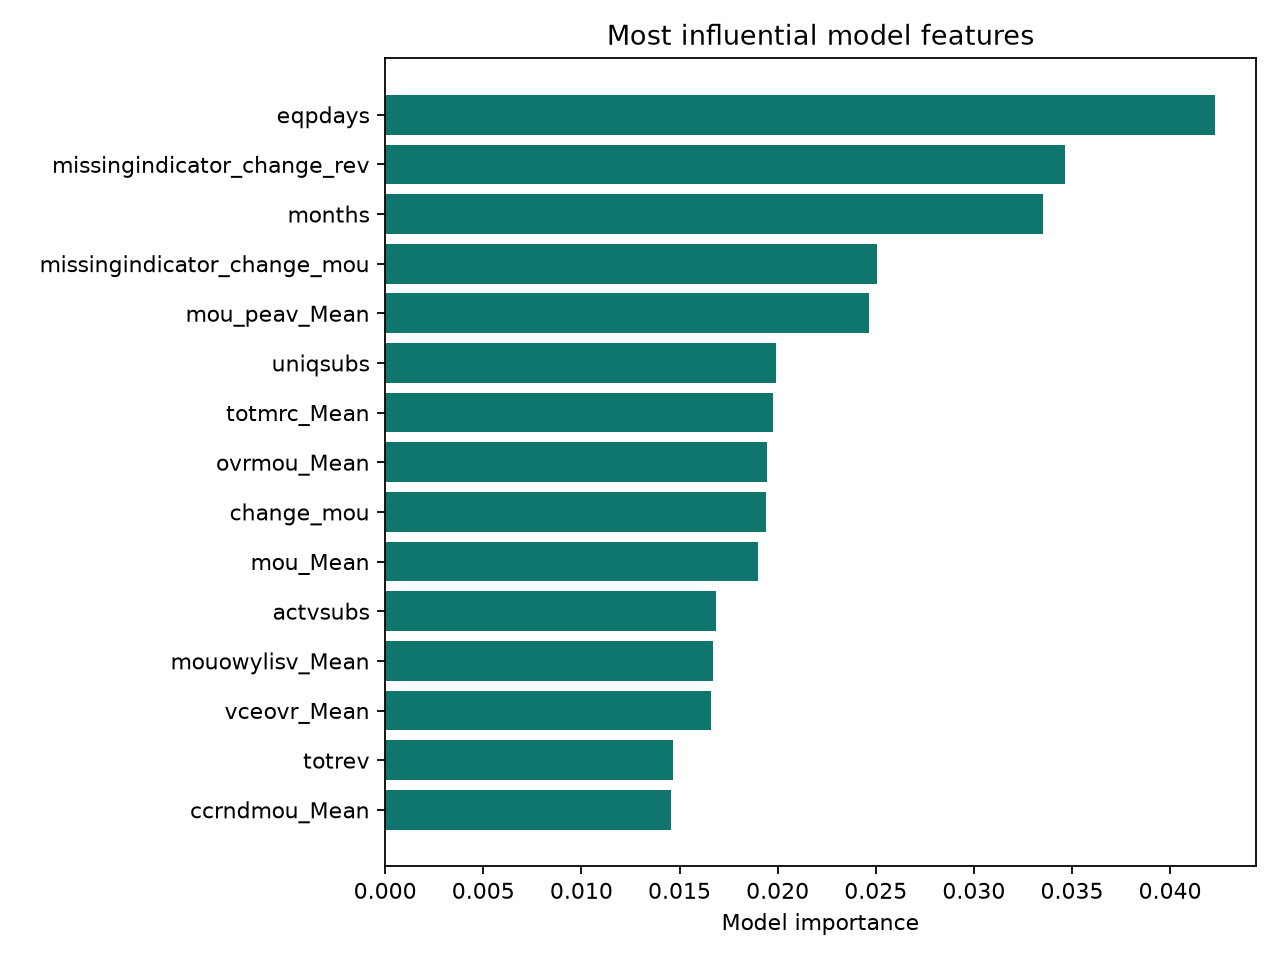

In [6]:
display(Image(filename=REPORTS / "figures" / "feature_importance.png"))

Equipment age, tenure, missingness and changes in usage are influential predictive
signals. Importance does not establish causality. A randomized retention experiment
is required to estimate whether acting on a signal improves customer outcomes.

## 7. Responsible AI and next steps

The model excludes customer identifiers and demographic, household, geographic,
and credit-related fields. Deployment would still require governed fairness audits,
calibration review, drift monitoring, human oversight, and an A/B test of any
retention intervention.

See `docs/responsible-ai.md` and `docs/model-card.md` for the full assessment.